In [1]:
from playground import Playground

[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO: Successfully loaded OpenSpiel environments: 16.
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_backgammon
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_checkers
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_chess
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_connect_four
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_gin_rummy
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_go
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_goofspiel
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_hearts
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_hex
[kaggle_environments.envs.open_spiel_env.open_spiel_env] INFO:    open_spiel_matching_pennies_3p
[kaggle_environments.envs.

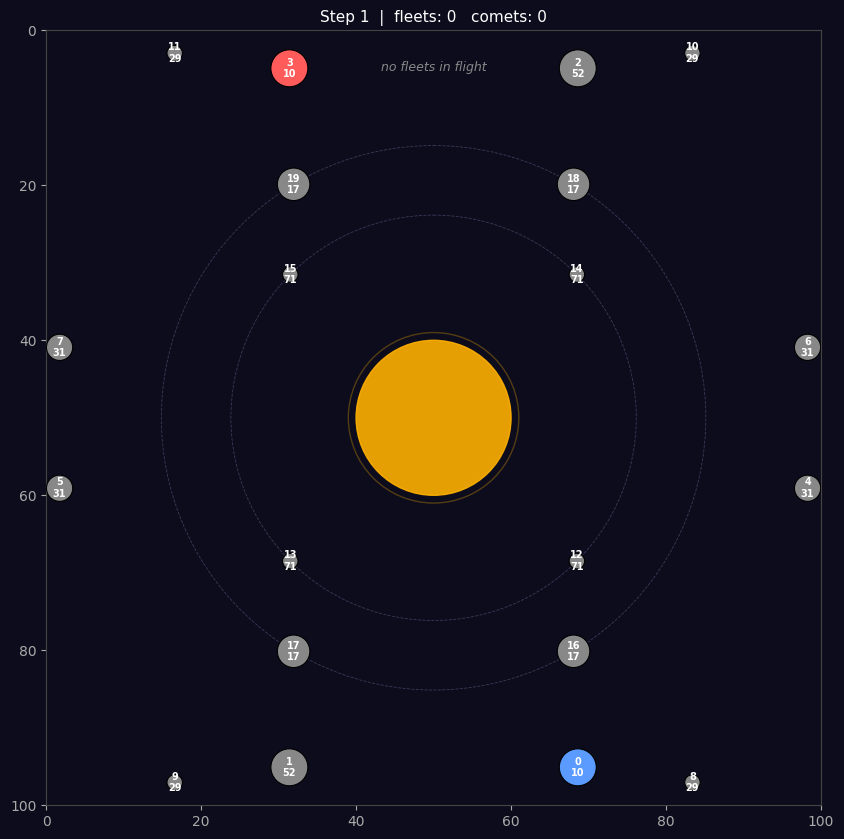

 ID  Owner  Kind         X       Y  Ships  Prod   rSun
------------------------------------------------------------
  0  ME     static    68.6    95.1     10     4   48.8
 12  Neut   rot       68.5    68.5     71     1   26.2
 13  Neut   rot       31.5    68.5     71     1   26.2
 14  Neut   rot       68.5    31.5     71     1   26.2
 15  Neut   rot       31.5    31.5     71     1   26.2
 16  Neut   rot       68.1    80.1     17     3   35.1
 17  Neut   rot       31.9    80.1     17     3   35.1
 18  Neut   rot       68.1    19.9     17     3   35.1
 19  Neut   rot       31.9    19.9     17     3   35.1
  1  Neut   static    31.4    95.1     52     4   48.8
  2  Neut   static    68.6     4.9     52     4   48.8
  3  P1     static    31.4     4.9     10     4   48.8
  4  Neut   static    98.3    59.1     31     2   49.1
  5  Neut   static     1.7    59.1     31     2   49.1
  6  Neut   static    98.3    40.9     31     2   49.1
  7  Neut   static     1.7    40.9     31     2   49.1
  8 

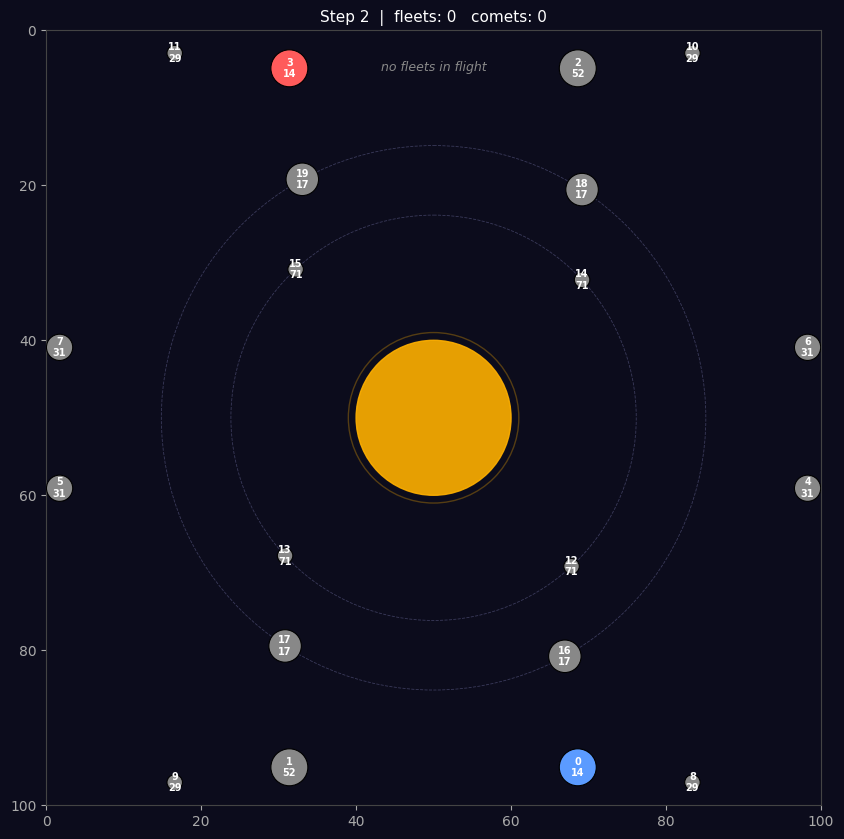

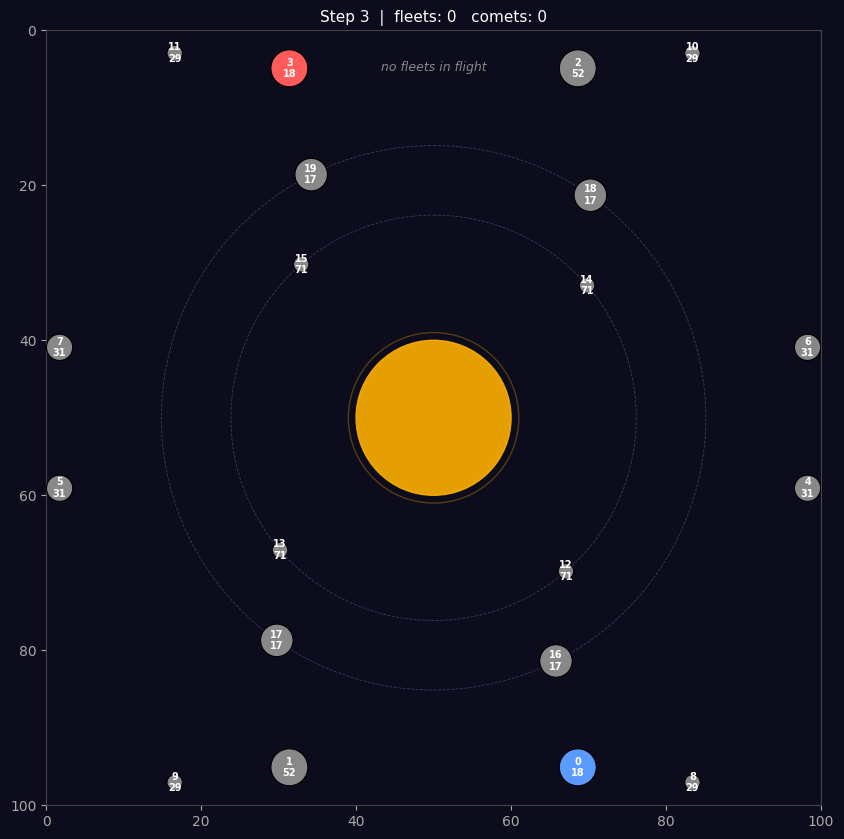

In [2]:
pg = Playground()
pg.render()
pg.planet_table()         # 0 senin, 7 nötr olsun
pg.launch(0, 7, ships=8)  # otomatik açı + ETA print
pg.step()                 # tur ilerlet
pg.render()               # filo havada, kesikli yörünge görünür
pg.step(); pg.render()    # ETA dolunca filo yok olur, gezegen sahibi değişir

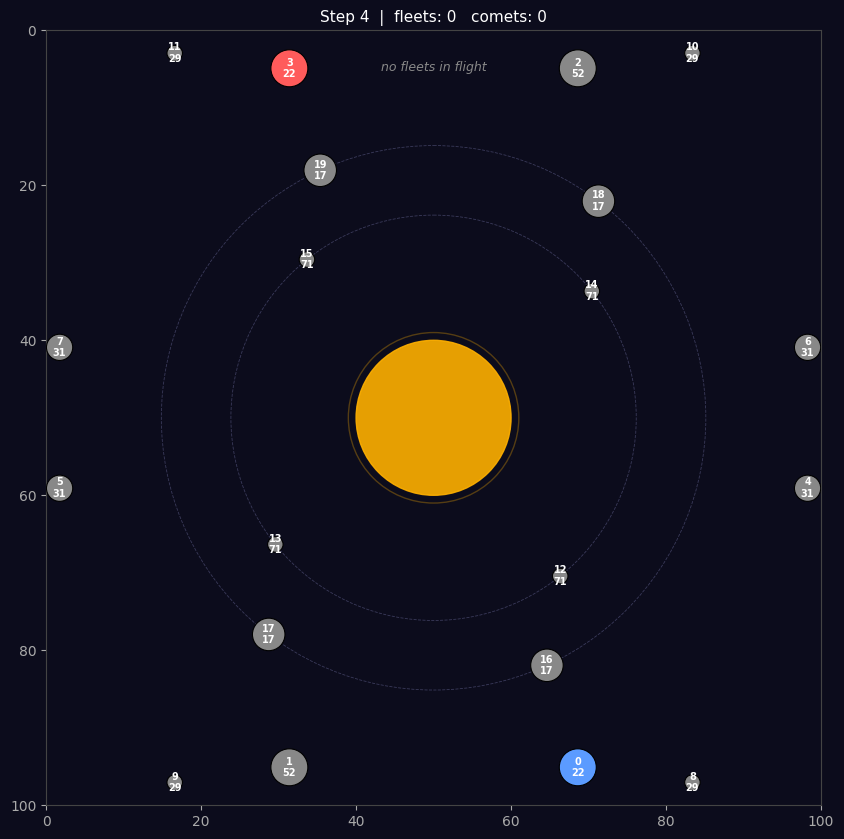

In [3]:
pg.step(); pg.render() 

In [4]:
result = pg.launch(src_id=4, tgt_id=8, ships=20) 

  planet 4 not owned by P0 (owner=-1)


(no fleets in flight)


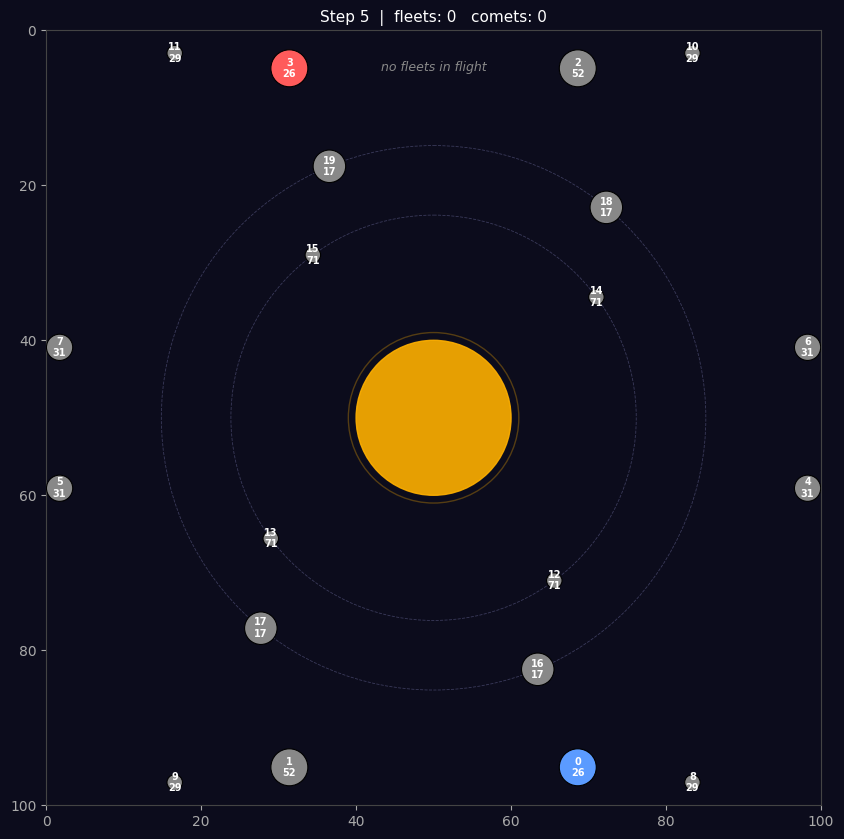

In [5]:
pg.step()                        # filo şimdi env'de spawn oldu
pg.fleet_table()                 # filo tablosu — ID, ships, speed gözükür
pg.render()                      # üçgen ikonu görünür, "fleets: 1" başlıkta


In [11]:
result = pg.launch(src_id=0, tgt_id=17, ships=20) 

P0 step 7: planet 0 -> 17, 20 ships, angle=-131.8°, ETA=31.79 turns (expected arrival ~ step 39)


(no fleets in flight)


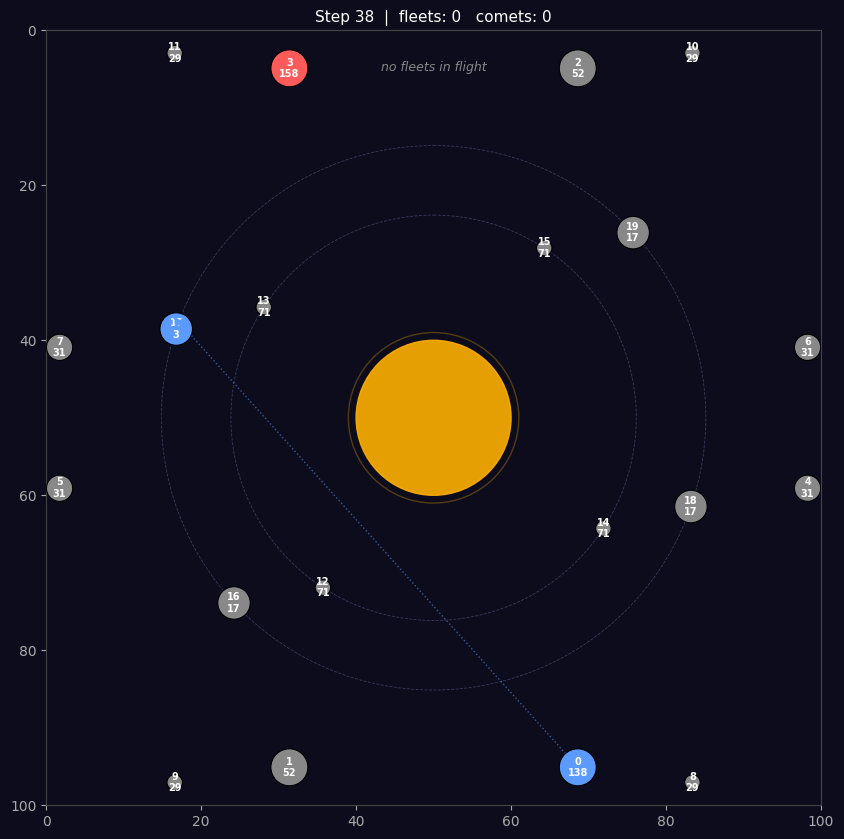

In [42]:
pg.step()                        # filo şimdi env'de spawn oldu
pg.fleet_table()                 # filo tablosu — ID, ships, speed gözükür
pg.render()                      # üçgen ikonu görünür, "fleets: 1" başlıkta

In [8]:
from navigation import find_intercepts, crosses_sun, path_collision, fleet_speed
import math

me = pg.obs["player"]
omega = pg.obs["angular_velocity"]
ps = pg.planets()
src = next(p for p in ps if p.id == 4)
tgt = next(p for p in ps if p.id == 15)
ships = 20

cands = find_intercepts(src, tgt, ships, omega, max_results=6)
print(f"Speed(20 ships) = {fleet_speed(ships):.3f}")
print(f"Intercept candidates: {len(cands)}")

for i, (t_star, ix, iy) in enumerate(cands):
    a = math.atan2(iy - src.y, ix - src.x)
    sx = src.x + math.cos(a) * (src.radius + 0.1)
    sy = src.y + math.sin(a) * (src.radius + 0.1)
    sun_hit = crosses_sun(sx, sy, ix, iy)
    blocker = path_collision(
        src, a, ships, t_star,
        [p for p in ps if p.id not in (src.id, tgt.id)],
        omega,
    )
    print(f"  #{i}: t*={t_star:6.2f}  intercept=({ix:5.1f},{iy:5.1f})  "
          f"sun={sun_hit}  blocker={blocker}")

Speed(20 ships) = 2.428
Intercept candidates: 1
  #0: t*= 22.51  intercept=( 55.9, 24.5)  sun=False  blocker=None


P0 step 69: planet 0 -> 17, 20 ships, angle=-82.0°, ETA=27.61 turns (expected arrival ~ step 97)
FID  Owner  Ships  From  -> Tgt     ETA
---------------------------------------------
  1  ME        20     0      17   25.50
(no incoming threats to player 0)


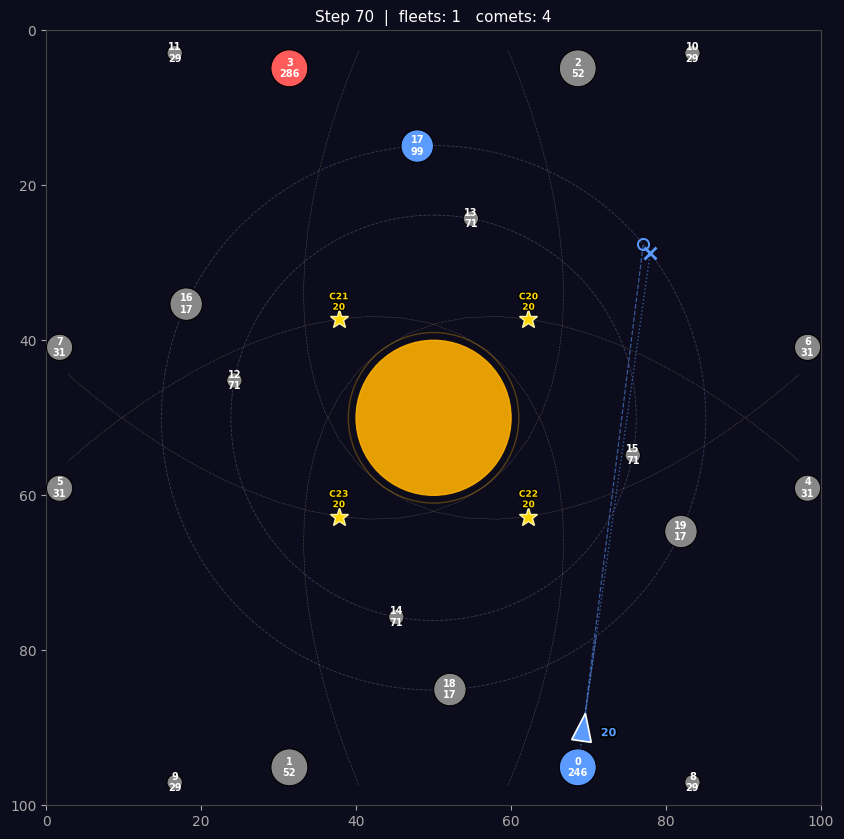

In [75]:
pg.launch(0, 17, ships=20)
pg.step()
pg.fleet_targets()    # tüm filolar + öngörülen hedef
pg.threats()          # gelen tehditler
pg.render()           # her filodan intercept'e kesikli çizgi

(no fleets in flight)
(no incoming threats to player 0)


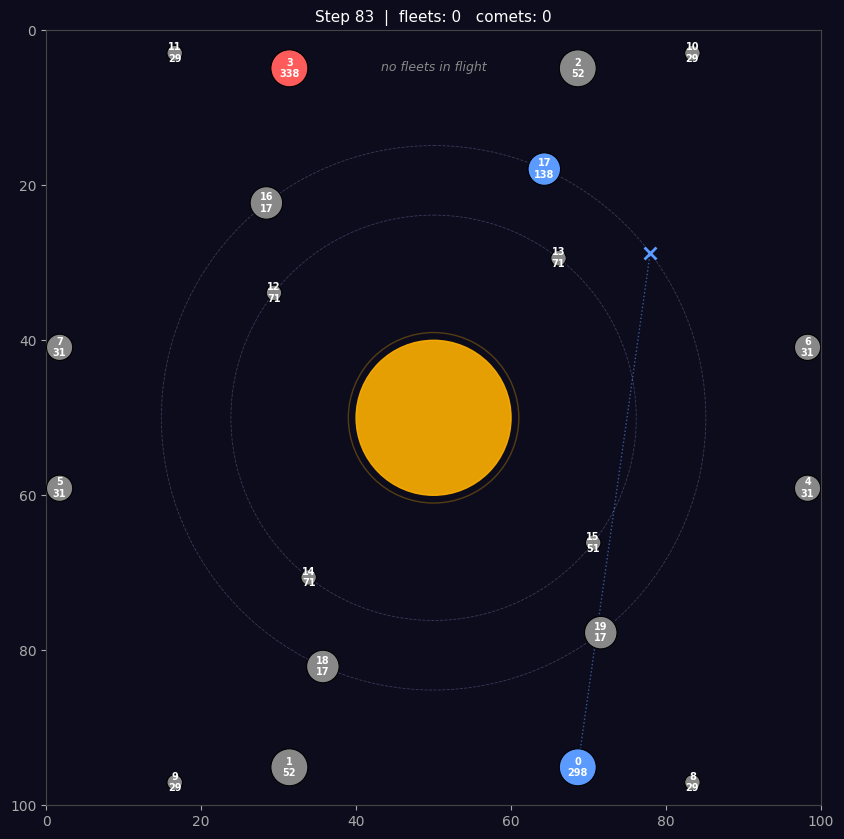

In [88]:
pg.step()
pg.fleet_targets()    # tüm filolar + öngörülen hedef
pg.threats()          # gelen tehditler
pg.render()  

In [89]:
# Aktif filolar (olmasa da sorun değil)
print("FLEETS:", [f for f in pg.fleets() if f.from_planet_id == 0])

# Gezegenler 0, 15, 17
for p in pg.planets():
    if p.id in (0, 15, 17):
        print(p, f"  radius={p.radius}")

# Launch kayıtları
print("\nHISTORY:")
for h in pg.history:
    print(h)

print("\nomega =", pg.obs["angular_velocity"])
print("step  =", pg.step_num)

FLEETS: []
Planet(id=0, owner=0, static, r=48.8, theta=+68deg, ships=298, prod=4)   radius=2.386294361119891
Planet(id=15, owner=-1, rot, r=26.2, theta=+38deg, ships=51, prod=1)   radius=1.0
Planet(id=17, owner=0, rot, r=35.1, theta=-66deg, ships=138, prod=3)   radius=2.09861228866811

HISTORY:
{'step': 7, 'player': 0, 'src_id': 0, 'tgt_id': 17, 'ships': 20, 'src_pos': (68.60863828631827, 95.09783068169907), 'intercept': (17.136594384169648, 37.588579695724356), 'angle': -2.3008543257989396, 'eta': 31.7877197265625, 'arrival_step': 39}
{'step': 69, 'player': 0, 'src_id': 0, 'tgt_id': 17, 'ships': 20, 'src_pos': (68.60863828631827, 95.09783068169907), 'intercept': (77.95013653246423, 28.72004110773275), 'angle': -1.4309822458870551, 'eta': 27.6082763671875, 'arrival_step': 97}

omega = 0.036833916252796396
step  = 83
